## 0. Install packages, load API key

In [2]:
%pip install -q census

Note: you may need to restart the kernel to use updated packages.


In [3]:
from census import Census
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import matplotlib as mpl

In [4]:
# Your key was saved to a file in Lab 3. This cell reads it; you do not paste it again.
try:
    with open(os.path.expanduser('~/census_key.txt')) as f:
        api_key = f.read().strip()
    print('Key loaded. It starts with:', api_key[:4] + '...')
except FileNotFoundError:
    print('No key file found. Open Lab 3, run the cell in Section 0.1 once to save your key, then run this cell again.')

c = Census(key=api_key)

Key loaded. It starts with: 0ca7...


## 1. Define functions
### 1.1 clean_acs

In [5]:
def clean_acs(df, id_cols=('NAME', 'GEO_ID', 'state', 'county', 'tract', 'place')):
    '''Convert estimate and MOE columns to numbers and replace jam values.

    Inputs:
    - df: a DataFrame straight from the Census API, with columns already renamed
    - id_cols: columns to leave as text (identifiers)

    Output: a cleaned copy of df.
    '''
    df = df.copy()
    numeric_cols = [col for col in df.columns if col not in id_cols]
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col])

    moe_cols = [col for col in numeric_cols if col.endswith('_moe')]

    # Controlled estimate: no sampling error, so the MOE is zero
    df[moe_cols] = df[moe_cols].replace(-555555555, 0)

    # No estimate available: missing, not zero
    df[numeric_cols] = df[numeric_cols].replace([-666666666, -222222222, -333333333], np.nan)

    return df

### 1.2 pull_geo

In [6]:
def pull_geo(geo_for, geo_in, variables, year):
    '''Pull one geography for one year and clean it.

    Inputs:
    - geo_for, geo_in: the geography, as in Lab 3 ('place:53000', 'state:06')
    - variables: a dictionary of variable codes to labels (default: the B03002 dictionary)
    - year: the final year of the 5-year period (default: ACS_YEAR)
    '''
    df = pd.DataFrame(
        c.acs5.get(list(variables.keys()), {'for': geo_for, 'in': geo_in}, year=year)
    ).rename(columns=variables)
    return clean_acs(df)

### 1.3 add_shares

In [7]:
def add_shares(df, groups, total='total'):
    df = df.copy()
    y = df[total]
    moe_y = df[f'{total}_moe']
    for g in groups:
        p = df[g] / y
        under_root = df[f'{g}_moe']**2 - p**2 * moe_y**2
        # Proportion formula; ratio formula (plus sign) if the value under the root is negative
        under_root = np.where(under_root < 0, df[f'{g}_moe']**2 + p**2 * moe_y**2, under_root)
        df[f'pct_{g}'] = p * 100
        df[f'pct_{g}_moe'] = under_root**0.5 / y * 100
    return df

### 1.4 combine_categories

In [8]:
def combine_categories(df, new_name, cols):
    '''Add a combined category column (and its MOE) to df, keeping the originals.

    Inputs:
    - df: a DataFrame with estimate columns in cols and matching <col>_moe columns
    - new_name: name of the new column, for example 'nh_other'
    - cols: list of estimate column names to combine

    Output: df with two new columns, new_name and new_name + '_moe'.
    '''
    df = df.copy()
    moe_cols = [f'{col}_moe' for col in cols]
    df[new_name] = df[cols].sum(axis='columns')
    df[f'{new_name}_moe'] = (df[moe_cols]**2).sum(axis='columns')**0.5
    return df

### 1.5 aggregate_tracts

In [9]:
def aggregate_tracts(df, name):
    '''Add up a DataFrame of tracts into one neighborhood row.

    Estimates are summed. Margins of error are combined by root sum of squares.
    Identifier columns are dropped and NAME is set to the neighborhood name.

    Inputs:
    - df: a cleaned DataFrame with one row per tract
    - name: the neighborhood name to put in the NAME column

    Output: a DataFrame with one row.
    '''
    numeric_cols = df.select_dtypes('number').columns
    moe_cols = [col for col in numeric_cols if col.endswith('_moe')]
    est_cols = [col for col in numeric_cols if col not in moe_cols]

    estimates = df[est_cols].sum()                    # plain sum
    moes = (df[moe_cols]**2).sum()**0.5               # root sum of squares

    row = pd.concat([estimates, moes])                # one long Series
    out = pd.DataFrame(row).transpose()               # make it a one-row table
    out.insert(0, 'NAME', name)
    out.insert(1, 'n_tracts', len(df))
    return out

### 1.6 z_statistic

In [10]:
def z_statistic(df, col, place_1, place_2):
    '''Two-sample Z for the difference between two ACS estimates.

    Inputs:
    - df: a DataFrame indexed by geography (or period) name, with col and col + '_se' columns
    - col: the column to compare (an estimate, usually a pct_ column)
    - place_1, place_2: the two row labels to compare

    Output: Z, the absolute difference divided by the root sum of squares of the two SEs.
    '''
    x1 = df.loc[place_1, col]
    x2 = df.loc[place_2, col]
    se1 = df.loc[place_1, col + '_se']
    se2 = df.loc[place_2, col + '_se']
    return abs(x1 - x2) / (se1**2 + se2**2)**0.5

### 1.7 long_table

In [11]:
def long_table(row, groups, labels, total='total'):
    '''Turn one geography row into a long table: one line per category.'''
    r = row.iloc[0]
    lines = []
    for g in groups:
        lines.append({
            'Category': labels[g],
            'Count': r[g],
            'Count MOE': r[f'{g}_moe'],
            'Percent': r[f'pct_{g}'],
            'Percent MOE': r[f'pct_{g}_moe'],
        })
    lines.append({'Category': labels[total] + ' (universe)', 'Count': r[total], 'Count MOE': r[f'{total}_moe'],
                  'Percent': 100.0, 'Percent MOE': np.nan})
    return pd.DataFrame(lines)

### 1.8 check_tracts_2019

In [12]:
def check_tracts_2019(tract_list, state, county, relationship_file):
    # Step 1: what does the 2019 table return for the 2020 numbers?
    df_2019 = pull_geo('tract:*', f'state:{state} county:{county}', {'NAME': 'NAME', 'B01001_001E': 'pop', 'B01001_001M': 'pop_moe'}, year=2019)
    found_2019 = set(df_2019['tract'])

    # Step 2: the 2010 tract(s) behind each 2020 tract, by share of the 2010 tract's land area
    cw = pd.read_csv(relationship_file, sep='|', dtype={'GEOID_TRACT_20': str, 'GEOID_TRACT_10': str}, encoding='utf-8-sig')
    cw['w10'] = cw['AREALAND_PART'] / cw['AREALAND_TRACT_10']
    cw = cw[cw['w10'] >= 0.02]          # ignore slivers under 2 percent of the 2010 tract's land

    list_2019, needs_crosswalk = [], False
    print(f'{"2020 tract":12}{"in 2019 table?":16}{"2010 source(s)":44}verdict')
    for t in tract_list:
        geoid20 = state + county + t
        sources = cw[cw['GEOID_TRACT_20'] == geoid20][['GEOID_TRACT_10', 'w10']]
        src = ', '.join(f'{g[5:]} ({w:.0%})' for g, w in sources.values)
        in_2019 = 'yes' if t in found_2019 else 'NO'
        if len(sources) == 1:
            g10, w = sources.iloc[0]
            t10 = g10[5:]
            # Did the rest of that 2010 tract go to other 2020 tracts? Then it was split.
            other_pieces = cw[(cw['GEOID_TRACT_10'] == g10) & (cw['GEOID_TRACT_20'] != geoid20)]
            if len(other_pieces) and other_pieces['w10'].max() >= 0.10:
                pieces = ', '.join(sorted(g[5:] for g in other_pieces['GEOID_TRACT_20']))
                verdict = f'split from {t10} (other pieces: {pieces}): use {t10} once for 2019'
            elif t10 == t:
                verdict = 'unchanged' if w > 0.98 else f'unchanged (edge adjusted; {1 - w:.0%} of its 2010 land moved to a neighbor)'
            else:
                verdict = f'renumbered: use {t10} for 2019'
            if t10 not in list_2019:
                list_2019.append(t10)
        else:
            verdict = 'more than one 2010 source: merged or boundary moved; city/county path or crosswalk companion'
            needs_crosswalk = True
        print(f'{t:12}{in_2019:16}{src:44}{verdict}')

    print()
    if needs_crosswalk:
        print('At least one tract has no single 2010 counterpart. TRACT_LIST_2019 cannot be built by hand.')
        return None
    print(f'2010 list for the 2019 pull ({len(list_2019)} tracts): {list_2019}')
    return list_2019

### 1.9 add_ses

In [13]:
def add_ses(df):
    for col in df.columns:
        if col.endswith('_moe'):
            df[col[:-4] + '_se'] = df[col] / 1.645
    return df

### 1.10 median_from_bands

In [14]:
def median_from_bands(counts, bands):
    '''Median by linear interpolation within the band where the running total passes half.'''
    counts = np.array(counts, dtype=float)
    half = counts.sum() / 2
    running = 0.0
    for n, (low, high) in zip(counts, bands):
        if running + n >= half:
            if high is None:
                return None          # the median is in the top band: report "$200,000 or more"
            return low + (half - running) / n * (high - low)
        running += n
    return None

### 1.11 short_name

In [15]:
def short_name(name):
    '''"Oakland city, California" -> "Oakland"; "Alameda County, California" -> "Alameda County".'''
    return str(name).split(',')[0].replace(' city', '').strip()

### 1.12 bar_with_moe

In [16]:
def bar_with_moe(df, col, rows, ylabel, filename=None, colors=None, dollars=False, figsize=(6, 4)):
    '''Bar chart with 90 percent MOE error bars and data labels.

    df: DataFrame indexed by place (or period) name, with col and col + '_moe'
    rows: the row labels to draw, in order (your neighborhood first)
    ylabel: the universe, in words
    filename: if given, saves a 300 dpi PNG
    colors: one color per bar (default: neighborhood coral, then dark blue, then light blue)
    dollars: True for dollar values
    '''
    values = df.loc[rows, col].astype(float)
    moes = df.loc[rows, f'{col}_moe'].astype(float)
    if colors is None:
        colors = [NBHD_COLOR, COMP_COLOR, THIRD_COLOR][:len(rows)]
    fmt = '${:,.0f}' if dollars else '{:.1f}'

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar([short_name(r) for r in rows], values, color=colors,
                  yerr=moes, capsize=6, error_kw={'elinewidth': 1.5}, width=0.6)
    label_colors = ['black' if c == THIRD_COLOR else 'white' for c in colors]
    for bar, v, lc in zip(bars, values, label_colors):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2, fmt.format(v),
                ha='center', va='center', color=lc, fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, (values + moes).max() * 1.15)
    if dollars:
        ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
    fig.tight_layout()
    if filename:
        fig.savefig(filename, dpi=300, bbox_inches='tight')
        print(f'Saved {filename}')
    return fig, ax

### 1.13 grouped_hbar

In [17]:
def grouped_hbar(df, groups, rows, labels, xlabel, filename=None, colors=None, figsize=(8, 6)):
    '''Horizontal grouped bars for several shares, two or three places, with MOE error bars.

    Sorted by the first place's shares (largest at the top). Data labels sit past the error bars.
    '''
    if colors is None:
        colors = [NBHD_COLOR, COMP_COLOR, THIRD_COLOR][:len(rows)]
    order = groups
    y = np.arange(len(order))
    h = 0.8 / len(rows)
    fig, ax = plt.subplots(figsize=figsize)
    for i, (r, color) in enumerate(zip(rows, colors)):
        pos = y + (len(rows) - 1 - 2 * i) * h / 2          # first place on top within each group
        vals = np.array([df.loc[r, f'pct_{g}'] for g in order], dtype=float)
        errs = np.array([df.loc[r, f'pct_{g}_moe'] for g in order], dtype=float)
        ax.barh(pos, vals, height=h, color=color, xerr=errs, capsize=3,
                error_kw={'elinewidth': 1}, label=short_name(r))
        for p, v, e in zip(pos, vals, errs):
            ax.text(v + e + 0.6, p, f'{v:.1f}', va='center', fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels([labels[g] for g in order])
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, max(df.loc[r, f'pct_{g}'] + df.loc[r, f'pct_{g}_moe'] for r in rows for g in groups) * 1.15)
    handles, leg_labels = ax.get_legend_handles_labels()
    ax.legend(handles, leg_labels, frameon=False, loc='lower right')
    fig.tight_layout()
    if filename:
        fig.savefig(filename, dpi=300, bbox_inches='tight')
        print(f'Saved {filename}')
    return fig, ax

## 2. Define geographies
### 2.1 2024

In [18]:
NEIGHBORHOOD_NAME = 'Fruitvale'
TRACT_LIST = ['406100', '406202', '407200']

STATE = '06'          # California
COUNTY = '001'        # San Francisco County
PLACE = '53000'       # San Francisco
ACS_YEAR = 2024       # 2020 to 2024 5-year estimates

### 2.1 2019

In [19]:
RELATIONSHIP_FILE = '~/PlanningMethods2026/Week06_Lab_StatisticalSignificance/tab20_tract20_tract10_st06.txt'

In [20]:
TRACT_LIST_2019 = check_tracts_2019(TRACT_LIST, STATE, COUNTY, RELATIONSHIP_FILE)

2020 tract  in 2019 table?  2010 source(s)                              verdict
406100      yes             406100 (100%)                               unchanged
406202      yes             406202 (100%)                               unchanged
407200      yes             407200 (100%)                               unchanged

2010 list for the 2019 pull (3 tracts): ['406100', '406202', '407200']


## 3. Define variables
### 3.1 race/ethnicity

In [21]:
race_vars = {
    'NAME': 'NAME',
    'GEO_ID': 'GEO_ID',
    'B03002_001E': 'total',
    'B03002_001M': 'total_moe',
    'B03002_003E': 'nh_white',
    'B03002_003M': 'nh_white_moe',
    'B03002_004E': 'nh_black',
    'B03002_004M': 'nh_black_moe',
    'B03002_005E': 'nh_native',
    'B03002_005M': 'nh_native_moe',
    'B03002_006E': 'nh_asian',
    'B03002_006M': 'nh_asian_moe',
    'B03002_007E': 'nh_pi',
    'B03002_007M': 'nh_pi_moe',
    'B03002_008E': 'nh_1other',
    'B03002_008M': 'nh_1other_moe',
    'B03002_009E': 'nh_multi',
    'B03002_009M': 'nh_multi_moe',
    'B03002_012E': 'hispanic',
    'B03002_012M': 'hispanic_moe',
}

# The eight race and ethnicity groups, in the order we will report them
GROUPS = ['hispanic', 'nh_white', 'nh_black', 'nh_native', 'nh_asian', 'nh_pi', 'nh_1other', 'nh_multi']

LABELS = {
    'hispanic':  'Hispanic or Latino (any race)',
    'nh_white':  'White alone, not Hispanic',
    'nh_black':  'Black or African American alone, not Hispanic',
    'nh_native': 'American Indian and Alaska Native alone, not Hispanic',
    'nh_asian':  'Asian alone, not Hispanic',
    'nh_pi':     'Native Hawaiian and Other Pacific Islander alone, not Hispanic',
    'nh_1other': 'Some other race alone, not Hispanic',
    'nh_multi':  'Two or more races, not Hispanic',
    'total':     'Total population',
}

NEW_GROUPS = ['hispanic', 'nh_white', 'nh_black', 'nh_asian', 'nh_other']

NEW_LABELS = {
    'hispanic':  'Hispanic or Latino (any race)',
    'nh_white':  'White alone, not Hispanic',
    'nh_black':  'Black or African American alone, not Hispanic',
    'nh_asian':  'Asian alone, not Hispanic',
    'nh_other':  'Other race or two or more races, not Hispanic',
    'total':     'Total population',
}

### 3.2 income
#### median income

In [22]:
med_income_vars = {
    'NAME': 'NAME',
    'GEO_ID': 'GEO_ID',
    'B19013_001E': 'med_hh_income',
    'B19013_001M': 'med_hh_income_moe',
}

#### income distribution

In [23]:
income_dist_vars = {
    'NAME': 'NAME',
    'GEO_ID': 'GEO_ID',
    'B19001_001E': 'total',
    'B19001_001M': 'total_moe',
    'B19001_002E': 'under_10',
    'B19001_002M': 'under_10_moe',
    'B19001_003E': 'btw_10_15',
    'B19001_003M': 'btw_10_15_moe',
    'B19001_004E': 'btw_15_20',
    'B19001_004M': 'btw_15_20_moe',
    'B19001_005E': 'btw_20_25',
    'B19001_005M': 'btw_20_25_moe',
    'B19001_006E': 'btw_25_30',
    'B19001_006M': 'btw_25_30_moe',
    'B19001_007E': 'btw_30_35',
    'B19001_007M': 'btw_30_35_moe',
    'B19001_008E': 'btw_35_40',
    'B19001_008M': 'btw_35_40_moe',
    'B19001_009E': 'btw_40_45',
    'B19001_009M': 'btw_40_45_moe',
    'B19001_010E': 'btw_45_50',
    'B19001_010M': 'btw_45_50_moe',
    'B19001_011E': 'btw_50_60',
    'B19001_011M': 'btw_50_60_moe',
    'B19001_012E': 'btw_60_75',
    'B19001_012M': 'btw_60_75_moe',
    'B19001_013E': 'btw_75_100',
    'B19001_013M': 'btw_75_100_moe',
    'B19001_014E': 'btw_100_125',
    'B19001_014M': 'btw_100_125_moe',
    'B19001_015E': 'btw_125_150',
    'B19001_015M': 'btw_125_150_moe',
    'B19001_016E': 'btw_150_200',
    'B19001_016M': 'btw_150_200_moe',
    'B19001_017E': 'over_200',
    'B19001_017M': 'over_200_moe'
}

### 3.3 poverty

In [24]:
poverty_vars = {
    'NAME': 'NAME',
    'GEO_ID': 'GEO_ID',
    'B17001_001E': 'pov_universe',
    'B17001_001M': 'pov_universe_moe',
    'B17001_002E': 'below_poverty',
    'B17001_002M': 'below_poverty_moe',
}

### 3.4 housing tenure

In [25]:
tenure_vars = {
    'NAME': 'NAME',
    'GEO_ID': 'GEO_ID',
    'B25003_001E': 'units',
    'B25003_001M': 'units_moe',
    'B25003_002E': 'owner',
    'B25003_002M': 'owner_moe',
    'B25003_003E': 'renter',
    'B25003_003M': 'renter_moe',
}

TENURE_GROUPS = ['renter', 'owner']

### 3.5 median rent

In [26]:
med_rent_vars = {
    'NAME': 'NAME',
    'GEO_ID': 'GEO_ID',
    'B25064_001E': 'med_rent',
    'B25064_001M': 'med_rent_moe',
}

### 3.6 rent distribution (2015-2019 and 2020-2024)

In [27]:
rent_dist_vars = {
    'NAME': 'NAME',
    'GEO_ID': 'GEO_ID',
    'B25063_001E': 'total',
    'B25063_001M': 'total_moe',
    'B25063_002E': 'total_wc',
    'B25063_002M': 'total_wc_moe',
    'B25063_003E': 'under_100',
    'B25063_003M': 'under_100_moe',
    'B25063_004E': 'btw_100_150',
    'B25063_004M': 'btw_100_150_moe',
    'B25063_005E': 'btw_150_200',
    'B25063_005M': 'btw_150_200_moe',
    'B25063_006E': 'btw_200_250',
    'B25063_006M': 'btw_200_250_moe',
    'B25063_007E': 'btw_250_300',
    'B25063_007M': 'btw_250_300_moe',
    'B25063_008E': 'btw_300_350',
    'B25063_008M': 'btw_300_350_moe',
    'B25063_009E': 'btw_350_400',
    'B25063_009M': 'btw_350_400_moe',
    'B25063_010E': 'btw_400_450',
    'B25063_010M': 'btw_400_450_moe',
    'B25063_011E': 'btw_450_500',
    'B25063_011M': 'btw_450_500_moe',
    'B25063_012E': 'btw_500_550',
    'B25063_012M': 'btw_500_550_moe',
    'B25063_013E': 'btw_550_600',
    'B25063_013M': 'btw_550_600_moe',
    'B25063_014E': 'btw_600_650',
    'B25063_014M': 'btw_600_650_moe',
    'B25063_015E': 'btw_650_700',
    'B25063_015M': 'btw_650_700_moe',
    'B25063_016E': 'btw_700_750',
    'B25063_016M': 'btw_700_750_moe',
    'B25063_017E': 'btw_750_800',
    'B25063_017M': 'btw_750_800_moe',
    'B25063_018E': 'btw_800_900',
    'B25063_018M': 'btw_800_900_moe',
    'B25063_019E': 'btw_900_1000',
    'B25063_019M': 'btw_900_1000_moe',   
    'B25063_020E': 'btw_1000_1250',
    'B25063_020M': 'btw_1000_1250_moe',
    'B25063_021E': 'btw_1250_1500',
    'B25063_021M': 'btw_1250_1500_moe',
    'B25063_022E': 'btw_1500_2000',
    'B25063_022M': 'btw_1500_2000_moe',
    'B25063_023E': 'btw_2000_2500',
    'B25063_023M': 'btw_2000_2500_moe',
    'B25063_024E': 'btw_2500_3000',
    'B25063_024M': 'btw_2500_3000_moe',
    'B25063_025E': 'btw_3000_3500',
    'B25063_025M': 'btw_3000_3500_moe',
    'B25063_026E': 'over_3500',
    'B25063_026M': 'over_3500_moe',
    'B25063_027E': 'no_cash_rent',
    'B25063_027M': 'no_cash_rent_moe',
}

### 3.7 rent burden (2015-2019 and 2020-2024)

In [28]:
burden_vars = {
    'NAME': 'NAME',
    'GEO_ID': 'GEO_ID',
    'B25070_001E': 'total',
    'B25070_001M': 'total_moe',
    'B25070_002E': 'under_10',
    'B25070_002M': 'under_10_moe',    
    'B25070_003E': 'btw_10_15',
    'B25070_003M': 'btw_10_15_moe',
    'B25070_004E': 'btw_15_20',
    'B25070_004M': 'btw_15_20_moe',
    'B25070_005E': 'btw_20_25',
    'B25070_005M': 'btw_20_25_moe',
    'B25070_006E': 'btw_25_30',
    'B25070_006M': 'btw_25_30_moe',
    'B25070_007E': 'btw_30_35',
    'B25070_007M': 'btw_30_35_moe',
    'B25070_008E': 'btw_35_40',
    'B25070_008M': 'btw_35_40_moe',
    'B25070_009E': 'btw_40_50',
    'B25070_009M': 'btw_40_50_moe',
    'B25070_010E': 'over_50',
    'B25070_010M': 'over_50_moe',
    'B25070_011E': 'nc',
    'B25070_011M': 'nc_moe',
}

BURDEN_GROUPS = ['no_burden', 'some_burden', 'high_burden']

BURDEN_LABELS = {'no_burden': 'no burden', 
                 'some_burden': 'some burden', 
                 'high_burden': 'high burden',
                'total': 'total'}

## 4. Pull and clean data (2020-2024 ACS)
### 4.1 race/ethnicity

In [29]:
race_county = pull_geo(f'place:{PLACE}', f'state:{STATE}', race_vars, 2024)
race_county = combine_categories(race_county, 'nh_other', ['nh_native', 'nh_pi', 'nh_1other', 'nh_multi'])

race_tracts = pull_geo('tract:*', f'state:{STATE}', race_vars, 2024)
race_tracts_nbhd = race_tracts[race_tracts['tract'].isin(TRACT_LIST)]
race_tracts_nbhd = race_tracts_nbhd.loc[race_tracts_nbhd['county'] == COUNTY]
race_tracts_nbhd = combine_categories(race_tracts_nbhd, 'nh_other', ['nh_native', 'nh_pi', 'nh_1other', 'nh_multi'])

### 4.2 income
#### median income

In [30]:
med_income_county = pull_geo(f'place:{PLACE}', f'state:{STATE}', med_income_vars, 2024)
med_income_tracts = pull_geo('tract:*', f'state:{STATE}', med_income_vars, 2024)
med_income_tracts_nbhd = med_income_tracts[med_income_tracts['tract'].isin(TRACT_LIST)]
med_income_tracts_nbhd = med_income_tracts_nbhd.loc[med_income_tracts_nbhd['county'] == COUNTY]

#### income distribution

In [31]:
income_dist_county = pull_geo(f'place:{PLACE}', f'state:{STATE}', income_dist_vars, 2024)
income_dist_tracts = pull_geo('tract:*', f'state:{STATE}', income_dist_vars, 2024)
income_dist_tracts_nbhd = income_dist_tracts[income_dist_tracts['tract'].isin(TRACT_LIST)]
income_dist_tracts_nbhd = income_dist_tracts_nbhd.loc[income_dist_tracts_nbhd['county'] == COUNTY]

In [32]:
income_dist_county = combine_categories(income_dist_county, 'under_25',
                                        ['btw_10_15', 'btw_15_20',  'btw_20_25'])
income_dist_county = combine_categories(income_dist_county, 'btw_25_50', 
                                        ['btw_25_30', 'btw_30_35', 'btw_35_40', 
                                         'btw_40_45', 'btw_45_50'])
income_dist_county = combine_categories(income_dist_county, 'btw_50_75', 
                                        ['btw_50_60', 'btw_60_75'])

income_dist_tracts_nbhd = combine_categories(income_dist_tracts_nbhd, 'under_25',
                                        ['btw_10_15', 'btw_15_20',  'btw_20_25'])
income_dist_tracts_nbhd = combine_categories(income_dist_tracts_nbhd, 'btw_25_50', 
                                        ['btw_25_30', 'btw_30_35', 'btw_35_40', 
                                         'btw_40_45', 'btw_45_50'])
income_dist_tracts_nbhd = combine_categories(income_dist_tracts_nbhd, 'btw_50_75', 
                                        ['btw_50_60', 'btw_60_75'])

### 4.3 poverty

In [33]:
poverty_county = pull_geo(f'place:{PLACE}', f'state:{STATE}', poverty_vars, 2024)
poverty_tracts = pull_geo('tract:*', f'state:{STATE}', poverty_vars, 2024)
poverty_tracts_nbhd = poverty_tracts[poverty_tracts['tract'].isin(TRACT_LIST)]
poverty_tracts_nbhd = poverty_tracts_nbhd.loc[poverty_tracts_nbhd['county'] == COUNTY]

### 4.4 tenure

In [34]:
tenure_county = pull_geo(f'place:{PLACE}', f'state:{STATE}', tenure_vars, 2024)
tenure_tracts = pull_geo('tract:*', f'state:{STATE}', tenure_vars, 2024)
tenure_tracts_nbhd = tenure_tracts[tenure_tracts['tract'].isin(TRACT_LIST)]
tenure_tracts_nbhd = tenure_tracts_nbhd.loc[tenure_tracts_nbhd['county'] == COUNTY]

### 4.5 median rent

In [35]:
med_rent_county = pull_geo(f'place:{PLACE}', f'state:{STATE}', med_rent_vars, 2024)
med_rent_tracts = pull_geo('tract:*', f'state:{STATE}', med_rent_vars, 2024)
med_rent_tracts_nbhd = med_rent_tracts[med_rent_tracts['tract'].isin(TRACT_LIST)]
med_rent_tracts_nbhd = med_rent_tracts_nbhd.loc[med_rent_tracts_nbhd['county'] == COUNTY]

### 4.6 rent distribution
#### 2015-2019

In [36]:
rent_dist_county_19 = pull_geo(f'place:{PLACE}', f'state:{STATE}', rent_dist_vars, year = 2019)
rent_dist_tracts_19 = pull_geo('tract:*', f'state:{STATE}', rent_dist_vars, year = 2019)
rent_dist_tracts_nbhd_19 = rent_dist_tracts_19[rent_dist_tracts_19['tract'].isin(TRACT_LIST_2019)]
rent_dist_tracts_nbhd_19 = rent_dist_tracts_nbhd_19.loc[rent_dist_tracts_nbhd_19['county'] == COUNTY]


In [37]:
rent_dist_county_19 = combine_categories(rent_dist_county_19, 'under_500', 
                                         ['under_100', 'btw_150_200', 'btw_200_250', 'btw_250_300',
                                          'btw_300_350', 'btw_350_400', 'btw_400_450', 'btw_450_500'])
rent_dist_county_19 = combine_categories(rent_dist_county_19, 'btw_500_1000', 
                                         ['btw_500_550', 'btw_550_600', 'btw_600_650', 'btw_650_700',
                                          'btw_700_750', 'btw_750_800', 'btw_800_900', 'btw_900_1000'])
rent_dist_county_19 = combine_categories(rent_dist_county_19, 'btw_1000_1500', 
                                         ['btw_1000_1250', 'btw_1250_1500'])

rent_dist_tracts_nbhd_19 = combine_categories(rent_dist_tracts_nbhd_19, 'under_500', 
                                         ['under_100', 'btw_150_200', 'btw_200_250', 'btw_250_300',
                                          'btw_300_350', 'btw_350_400', 'btw_400_450', 'btw_450_500'])
rent_dist_tracts_nbhd_19 = combine_categories(rent_dist_tracts_nbhd_19, 'btw_500_1000', 
                                         ['btw_500_550', 'btw_550_600', 'btw_600_650', 'btw_650_700',
                                          'btw_700_750', 'btw_750_800', 'btw_800_900', 'btw_900_1000'])
rent_dist_tracts_nbhd_19 = combine_categories(rent_dist_tracts_nbhd_19, 'btw_1000_1500', 
                                         ['btw_1000_1250', 'btw_1250_1500'])


#### 2020-2024

In [38]:
rent_dist_county_24 = pull_geo(f'place:{PLACE}', f'state:{STATE}', rent_dist_vars, year = 2024)
rent_dist_tracts_24 = pull_geo('tract:*', f'state:{STATE}', rent_dist_vars, year = 2024)
rent_dist_tracts_nbhd_24 = rent_dist_tracts_24[rent_dist_tracts_24['tract'].isin(TRACT_LIST)]
rent_dist_tracts_nbhd_24 = rent_dist_tracts_nbhd_24.loc[rent_dist_tracts_nbhd_24['county'] == COUNTY]

In [39]:
rent_dist_county_24 = combine_categories(rent_dist_county_24, 'under_500', 
                                         ['under_100', 'btw_150_200', 'btw_200_250', 'btw_250_300',
                                          'btw_300_350', 'btw_350_400', 'btw_400_450', 'btw_450_500'])
rent_dist_county_24 = combine_categories(rent_dist_county_24, 'btw_500_1000', 
                                         ['btw_500_550', 'btw_550_600', 'btw_600_650', 'btw_650_700',
                                          'btw_700_750', 'btw_750_800', 'btw_800_900', 'btw_900_1000'])
rent_dist_county_24 = combine_categories(rent_dist_county_24, 'btw_1000_1500', 
                                         ['btw_1000_1250', 'btw_1250_1500'])

rent_dist_tracts_nbhd_24 = combine_categories(rent_dist_tracts_nbhd_24, 'under_500', 
                                         ['under_100', 'btw_150_200', 'btw_200_250', 'btw_250_300',
                                          'btw_300_350', 'btw_350_400', 'btw_400_450', 'btw_450_500'])
rent_dist_tracts_nbhd_24 = combine_categories(rent_dist_tracts_nbhd_24, 'btw_500_1000', 
                                         ['btw_500_550', 'btw_550_600', 'btw_600_650', 'btw_650_700',
                                          'btw_700_750', 'btw_750_800', 'btw_800_900', 'btw_900_1000'])
rent_dist_tracts_nbhd_24 = combine_categories(rent_dist_tracts_nbhd_24, 'btw_1000_1500', 
                                         ['btw_1000_1250', 'btw_1250_1500'])

### 4.7 rent burden
#### 2015-2019

In [40]:
# pull_geo(geo_for, geo_in, variables, year=2019)

burden_county_19 = pull_geo(f'place:{PLACE}', f'state:{STATE}', burden_vars, year = 2019)
burden_tracts_19 = pull_geo('tract:*', f'state:{STATE}', burden_vars, year = 2019)
burden_tracts_nbhd_19 = burden_tracts_19[burden_tracts_19['tract'].isin(TRACT_LIST_2019)]
burden_tracts_nbhd_19 = burden_tracts_nbhd_19.loc[burden_tracts_nbhd_19['county'] == COUNTY]

In [41]:
burden_county_19 = combine_categories(burden_county_19, 'no_burden', ['under_10', 'btw_10_15', 'btw_15_20', 'btw_20_25', 'btw_25_30'])
burden_county_19 = combine_categories(burden_county_19, 'some_burden', ['btw_30_35', 'btw_35_40', 'btw_40_50'])
burden_county_19 = combine_categories(burden_county_19, 'high_burden', ['over_50'])
burden_county_19 = add_shares(burden_county_19, BURDEN_GROUPS, 'total')

burden_tracts_nbhd_19 = combine_categories(burden_tracts_nbhd_19, 'no_burden', ['under_10', 'btw_10_15', 'btw_15_20', 'btw_20_25', 'btw_25_30'])
burden_tracts_nbhd_19 = combine_categories(burden_tracts_nbhd_19, 'some_burden', ['btw_30_35', 'btw_35_40', 'btw_40_50'])
burden_tracts_nbhd_19 = combine_categories(burden_tracts_nbhd_19, 'high_burden', ['over_50'])
burden_tracts_nbhd_19 = add_shares(burden_tracts_nbhd_19, BURDEN_GROUPS, 'total')

#### 2020-2024

In [42]:
burden_county_24 = pull_geo(f'place:{PLACE}', f'state:{STATE}', burden_vars, 2024)
burden_tracts_24 = pull_geo('tract:*', f'state:{STATE}', burden_vars, 2024)
burden_tracts_nbhd_24 = burden_tracts_24[burden_tracts_24['tract'].isin(TRACT_LIST)]
burden_tracts_nbhd_24 = burden_tracts_nbhd_24.loc[burden_tracts_nbhd_24['county'] == COUNTY]

In [43]:
burden_county_24 = combine_categories(burden_county_24, 'no_burden', ['under_10', 'btw_10_15', 'btw_15_20', 'btw_20_25', 'btw_25_30'])
burden_county_24 = combine_categories(burden_county_24, 'some_burden', ['btw_30_35', 'btw_35_40', 'btw_40_50'])
burden_county_24 = combine_categories(burden_county_24, 'high_burden', ['over_50'])
burden_county_24 = add_shares(burden_county_24, BURDEN_GROUPS, 'total')

burden_tracts_nbhd_24 = combine_categories(burden_tracts_nbhd_24, 'no_burden', ['under_10', 'btw_10_15', 'btw_15_20', 'btw_20_25', 'btw_25_30'])
burden_tracts_nbhd_24 = combine_categories(burden_tracts_nbhd_24, 'some_burden', ['btw_30_35', 'btw_35_40', 'btw_40_50'])
burden_tracts_nbhd_24 = combine_categories(burden_tracts_nbhd_24, 'high_burden', ['over_50'])
burden_tracts_nbhd_24 = add_shares(burden_tracts_nbhd_24, BURDEN_GROUPS, 'total')

## 5. Aggregate neighborhood tract data, add percent SEs, run z-tests
### 5.1 race/ethnicity

In [44]:
race_nbhd_summary = aggregate_tracts(race_tracts_nbhd, 'Fruitvale')
race_comparison = pd.concat([race_nbhd_summary, race_county], ignore_index=True)
race_comparison = add_shares(race_comparison, NEW_GROUPS)
race_comparison = add_ses(race_comparison)

#### Tables: Race and Ethnicity

In [45]:
race_nbhd_table = long_table(race_comparison.loc[race_comparison['NAME'] == 'Fruitvale'], 
                             groups=NEW_GROUPS, labels=NEW_LABELS, total='total')

In [46]:
race_nbhd_table

,Category,Count,Count MOE,Percent,Percent MOE
0,Hispanic or Latino (any race),11403.0,1438.171408,64.282090,6.268087
1,"White alone, not Hispanic",1792.0,413.130730,10.102035,2.184253
2,"Black or African American alone, not Hispanic",1209.0,575.309482,6.815491,3.197038
3,"Asian alone, not Hispanic",2584.0,603.218866,14.566774,3.194651
4,"Other race or two or more races, not Hispanic",751.0,287.647354,4.233610,1.585795
5,Total population (universe),17739.0,1418.985905,100.000000,NaN


In [47]:
race_county_table = long_table(race_comparison.loc[race_comparison['NAME'] == 'Oakland city, California'], groups=NEW_GROUPS, labels=NEW_LABELS, total='total')

In [48]:
race_county_table

,Category,Count,Count MOE,Percent,Percent MOE
0,Hispanic or Latino (any race),126186.0,2872.000000,28.716621,0.653558
1,"White alone, not Hispanic",122006.0,2465.000000,27.765362,0.560932
2,"Black or African American alone, not Hispanic",86626.0,2474.000000,19.713803,0.562999
3,"Asian alone, not Hispanic",68848.0,2198.000000,15.667997,0.500194
4,"Other race or two or more races, not Hispanic",35752.0,2106.238116,8.136217,0.479321
5,Total population (universe),439418.0,102.000000,100.000000,NaN


#### Z-test: Race/ethnicity share (Hispanic)

In [49]:
race_comparison[['NAME', 'pct_hispanic', 'pct_hispanic_moe', 'pct_hispanic_se']]

,NAME,pct_hispanic,pct_hispanic_moe,pct_hispanic_se
0,Fruitvale,64.282090,6.268087,3.810387
1,"Oakland city, California",28.716621,0.653558,0.397300


In [50]:
z_statistic(race_comparison, 'pct_hispanic', 0, 1)

np.float64(9.28349359490625)

### 5.2 tenure

In [51]:
tenure_nbhd_summary = aggregate_tracts(tenure_tracts_nbhd, NEIGHBORHOOD_NAME)
tenure_comparison = pd.concat([tenure_nbhd_summary, tenure_county], ignore_index=True)
tenure_comparison = add_shares(tenure_comparison, TENURE_GROUPS, 'units')

for col in tenure_comparison.columns:
    if col.startswith('pct_') & col.endswith('_moe'):
        tenure_comparison[col[:-4] + '_se'] = tenure_comparison[col] / 1.645

#### Table: Tenure

In [52]:
tenure_comparison[['NAME', 'pct_renter', 'pct_renter_moe', 'pct_renter_se']]

,NAME,pct_renter,pct_renter_moe,pct_renter_se
0,Fruitvale,75.330639,5.139343,3.124221
1,"Oakland city, California",57.667173,0.810899,0.492947


#### Z-test: renter share

In [53]:
z_statistic(tenure_comparison, 'pct_renter', 0, 1)

np.float64(5.584631257170352)

### 5.3 median gross rent
#### Table inputs: range and simple average approximation for neighborhood, published values for county

In [54]:
n_with_median = med_rent_tracts_nbhd['med_rent'].notna().sum()

print(f'Range of tract medians: ${med_rent_tracts_nbhd["med_rent"].min():,.0f} to ${med_rent_tracts_nbhd["med_rent"].max():,.0f}')
print(f'Range of tract MOEs: ${med_rent_tracts_nbhd["med_rent_moe"].min():,.0f} to ${med_rent_tracts_nbhd["med_rent_moe"].max():,.0f}')

print(f'Average of tract medians (approximation): ${med_rent_tracts_nbhd["med_rent"].mean():,.0f} '
      f'(average MOE ${med_rent_tracts_nbhd["med_rent_moe"].mean():,.0f})')

print(f'{med_rent_county["NAME"].iloc[0]}: ${med_rent_county["med_rent"].iloc[0]:,.0f} (MOE ${med_rent_county["med_rent_moe"].iloc[0]:,.0f})')


Range of tract medians: $1,475 to $1,946
Range of tract MOEs: $137 to $383
Average of tract medians (approximation): $1,752 (average MOE $257)
Oakland city, California: $1,979 (MOE $29)


#### bar chart with MOEs

In [55]:
med_rent_plot_dict = {'name': [NEIGHBORHOOD_NAME, 'San Francisco'],
    'med_rent': [med_rent_tracts_nbhd['med_rent'].mean(), med_rent_county['med_rent'].iloc[0]],
    'med_rent_moe': [med_rent_tracts_nbhd['med_rent_moe'].mean(), med_rent_county['med_rent_moe'].iloc[0]],
    }
med_rent_plot_df = pd.DataFrame(data=med_rent_plot_dict)

In [56]:
med_rent_plot_df

,name,med_rent,med_rent_moe
0,Fruitvale,1752.0,257.0
1,San Francisco,1979.0,29.0


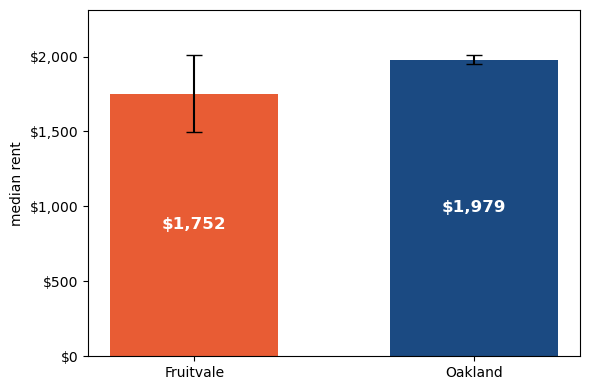

In [57]:
NBHD_COLOR = '#E85C34'    # coral: your neighborhood
COMP_COLOR = '#1B4A82'    # dark blue: the city or county
THIRD_COLOR = '#A9C3E0'   # light blue: a third geography, or the earlier period

med_rent_plot_df.index = ['Fruitvale', 'Oakland']

med_rent_plot = bar_with_moe(med_rent_plot_df, 'med_rent', list(med_rent_plot_df.index), 'median rent', dollars=True)

### 5.4 poverty 
#### Table: poverty rate, Fruitvale and Oakland

In [58]:
POVERTY_GROUPS = ['below_poverty']

poverty_nbhd_summary = aggregate_tracts(poverty_tracts_nbhd, NEIGHBORHOOD_NAME)
poverty_comparison = pd.concat([poverty_nbhd_summary, poverty_county], ignore_index=True)
poverty_comparison = add_shares(poverty_comparison, POVERTY_GROUPS, 'pov_universe')

for col in poverty_comparison.columns:
    if col.startswith('pct_') & col.endswith('_moe'):
        poverty_comparison[col[:-4] + '_se'] = poverty_comparison[col] / 1.645

In [59]:
poverty_comparison[['NAME', 'pct_below_poverty', 'pct_below_poverty_moe', 'pct_below_poverty_se']]

,NAME,pct_below_poverty,pct_below_poverty_moe,pct_below_poverty_se
0,Fruitvale,16.629483,4.697371,2.855544
1,"Oakland city, California",13.384229,0.656273,0.398950


#### Z-test: is the poverty rate in Fruitvale different from the Oakland average?

In [60]:
z_statistic(poverty_comparison, 'pct_below_poverty', 0, 1)

np.float64(1.1255430108635436)

### 5.5 median income
#### table inputs: range and simple average approximation for neighborhood, published values for county

In [61]:
n_with_median = med_income_tracts_nbhd['med_hh_income'].notna().sum()

print(f'Range of tract medians: ${med_income_tracts_nbhd["med_hh_income"].min():,.0f} to ${med_income_tracts_nbhd["med_hh_income"].max():,.0f}')
print(f'Range of tract MOEs: ${med_income_tracts_nbhd["med_hh_income_moe"].min():,.0f} to ${med_income_tracts_nbhd["med_hh_income_moe"].max():,.0f}')

print(f'Average of tract medians (approximation): ${med_income_tracts_nbhd["med_hh_income"].mean():,.0f} '
      f'(average MOE ${med_income_tracts_nbhd["med_hh_income_moe"].mean():,.0f})')

print(f'{med_income_county["NAME"].iloc[0]}: ${med_income_county["med_hh_income"].iloc[0]:,.0f} (MOE ${med_income_county["med_hh_income_moe"].iloc[0]:,.0f}')


Range of tract medians: $68,160 to $75,993
Range of tract MOEs: $9,136 to $23,665
Average of tract medians (approximation): $72,473 (average MOE $17,041)
Oakland city, California: $101,600 (MOE $2,146


#### bar chart with MOEs

(<Figure size 600x400 with 1 Axes>, <Axes: ylabel='median household income'>)

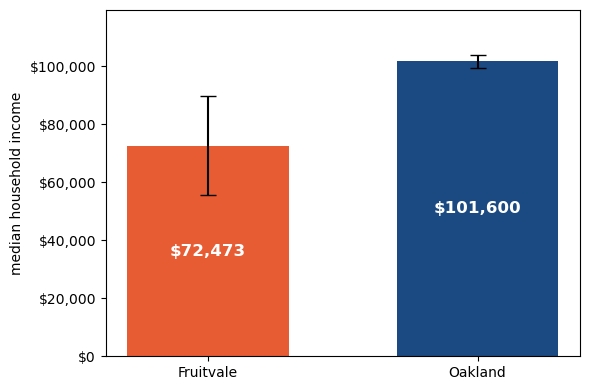

In [62]:
med_income_plot_dict = {'name': [NEIGHBORHOOD_NAME, 'San Francisco'],
    'med_hh_income': [med_income_tracts_nbhd["med_hh_income"].mean(), med_income_county["med_hh_income"].iloc[0]],
    'med_hh_income_moe': [med_income_tracts_nbhd["med_hh_income_moe"].mean(), med_income_county["med_hh_income_moe"].iloc[0]],
    }
med_income_plot_df = pd.DataFrame(data=med_income_plot_dict)

med_income_plot_df.index = [NEIGHBORHOOD_NAME, 'Oakland']

bar_with_moe(med_income_plot_df, 'med_hh_income', list(med_income_plot_df.index), 'median household income', dollars=True)

In [63]:
med_income_plot_dict = {'name': [NEIGHBORHOOD_NAME, 'San Francisco'],
    'med_hh_income': [med_income_tracts_nbhd["med_hh_income"].mean(), med_income_county["med_hh_income"].iloc[0]],
    'med_hh_income_moe': [med_income_tracts_nbhd["med_hh_income_moe"].mean(), med_income_county["med_hh_income_moe"].iloc[0]],
    }
med_income_plot_df = pd.DataFrame(data=med_income_plot_dict)

### 5.6 change over time: rent distribution
#### Tables: rent distribution, Fruitvale, 2019 and 2024

In [64]:
RENT_DIST_GROUPS = ['total_wc','under_500', 'btw_500_1000', 'btw_1000_1500', 'btw_1500_2000', 'btw_2000_2500', 
                    'btw_2500_3000', 'btw_3000_3500', 'over_3500']

RENT_DIST_LABELS = {'total_wc' : 'total',
                    'under_500': '$0-500', 
                    'btw_500_1000': '$500-1000', 
                    'btw_1000_1500': '$1000-1500', 
                    'btw_1500_2000': '$1500-2000', 
                    'btw_2000_2500': '$2000-2500', 
                    'btw_2500_3000': '$2500-3000', 
                    'btw_3000_3500': '$3000-3500', 
                    'over_3500': '$3500+'}

rent_dist_nbhd_summary_19 = aggregate_tracts(rent_dist_tracts_nbhd_19, '2015-2019')
rent_dist_nbhd_summary_24 = aggregate_tracts(rent_dist_tracts_nbhd_24, '2020-2024')

rent_dist_nbhd_comparison = pd.concat([rent_dist_nbhd_summary_19, rent_dist_nbhd_summary_24], ignore_index=True)
rent_dist_nbhd_comparison = add_shares(rent_dist_nbhd_comparison, groups=RENT_DIST_GROUPS, total='total_wc')

In [65]:
rent_dist_nbhd_table_2019 = long_table(rent_dist_nbhd_comparison.loc[rent_dist_nbhd_comparison['NAME'] == '2015-2019'],
                             groups = RENT_DIST_GROUPS, 
                             labels = RENT_DIST_LABELS,
                             total = 'total_wc')

In [66]:
rent_dist_nbhd_table_2024 = long_table(rent_dist_nbhd_comparison.loc[rent_dist_nbhd_comparison['NAME'] == '2020-2024'],
                             groups = RENT_DIST_GROUPS, 
                             labels = RENT_DIST_LABELS,
                             total = 'total_wc')

In [67]:
rent_dist_nbhd_table_2019.to_csv('rent_dist_nbhd_2019.csv')
rent_dist_nbhd_table_2024.to_csv('rent_dist_nbhd_2024.csv')

#### column charts

In [68]:
rent_dist_nbhd_comparison = rent_dist_nbhd_comparison.set_index("NAME")

Saved rent_dist_grouped_bar.png


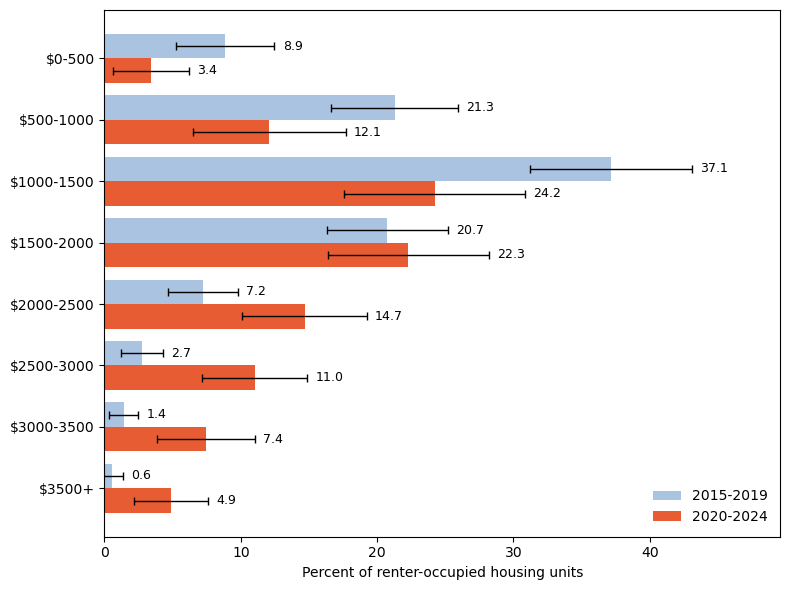

In [114]:
fig, ax = grouped_hbar(rent_dist_nbhd_comparison, list(reversed(RENT_DIST_GROUPS[1:])), ['2015-2019', '2020-2024'], RENT_DIST_LABELS, 'Percent of renter-occupied housing units',
                       filename='rent_dist_grouped_bar.png', colors = ['#A9C3E0', '#E85C34'])

#### Z-test: did the percent of renters paying over $3500 in rent increase between 2019 and 2024?

In [70]:
rent_dist_ztest = rent_dist_nbhd_comparison[['total_wc', 'total_wc_moe',
                                             'btw_2500_3000', 'btw_2500_3000_moe',
                           'btw_3000_3500', 'btw_3000_3500_moe',
                           'over_3500', 'over_3500_moe',
                           'pct_btw_3000_3500', 'pct_btw_3000_3500_moe', 
                           'pct_over_3500', 'pct_over_3500_moe']]

rent_dist_ztest = combine_categories(rent_dist_ztest, 'over_3000', ['btw_3000_3500', 'over_3500'])
rent_dist_ztest = combine_categories(rent_dist_ztest, 'over_2500', ['btw_2500_3000', 'btw_3000_3500', 'over_3500'])

rent_dist_ztest = add_shares(rent_dist_ztest, ['over_2500', 'over_3000'], 'total_wc')
rent_dist_ztest = add_ses(rent_dist_ztest)

In [71]:
rent_dist_ztest[['pct_over_3000', 'pct_over_3000_moe']]

,pct_over_3000,pct_over_3000_moe
NAME,,
2015-2019,1.997147,1.308235
2020-2024,12.323682,4.433471


In [72]:
z_statistic(rent_dist_ztest, 'pct_over_3000', '2015-2019', '2020-2024')

np.float64(3.674914629770174)

In [73]:
x1 = rent_dist_ztest.loc['2015-2019', 'pct_over_2500']
x2 = rent_dist_ztest.loc['2020-2024', 'pct_over_3000']
se1 = rent_dist_ztest.loc['2015-2019', 'pct_over_2500_se']
se2 = rent_dist_ztest.loc['2020-2024', 'pct_over_3000_se']

abs(x1 - x2)/(se1**2 + se2**2)**0.5

np.float64(2.5604760505024897)

### 5.7 change over time: rent burden
#### table: rent burden, 2015-2019 vs. 2020-2024, city/county

In [74]:
burden_nbhd_summary_19 = aggregate_tracts(burden_tracts_nbhd_19, '2015-2019')
burden_nbhd_summary_24 = aggregate_tracts(burden_tracts_nbhd_24, '2020-2024')

burden_nbhd_comparison = pd.concat([burden_nbhd_summary_19, burden_nbhd_summary_24], ignore_index=True)
burden_nbhd_comparison = add_shares(burden_nbhd_comparison, groups=BURDEN_GROUPS, total='total')
burden_nbhd_comparison = add_ses(burden_nbhd_comparison)

In [75]:
burden_table_2019 = long_table(burden_nbhd_comparison.loc[burden_nbhd_comparison['NAME'] == '2015-2019'],
                             groups = BURDEN_GROUPS, 
                             labels = BURDEN_LABELS,
                             total = 'total')

In [76]:
burden_table_2024 = long_table(burden_nbhd_comparison.loc[burden_nbhd_comparison['NAME'] == '2020-2024'],
                             groups = BURDEN_GROUPS, 
                             labels = BURDEN_LABELS,
                             total = 'total')

#### Z-test: did the percent of renters spending over 50% of their income on rent change between 2019-2024?

In [77]:
z_statistic(burden_nbhd_comparison, 'pct_high_burden', 0, 1)

np.float64(0.2301130748192334)

#### column charts

Saved burden_dist_grouped_bar.png


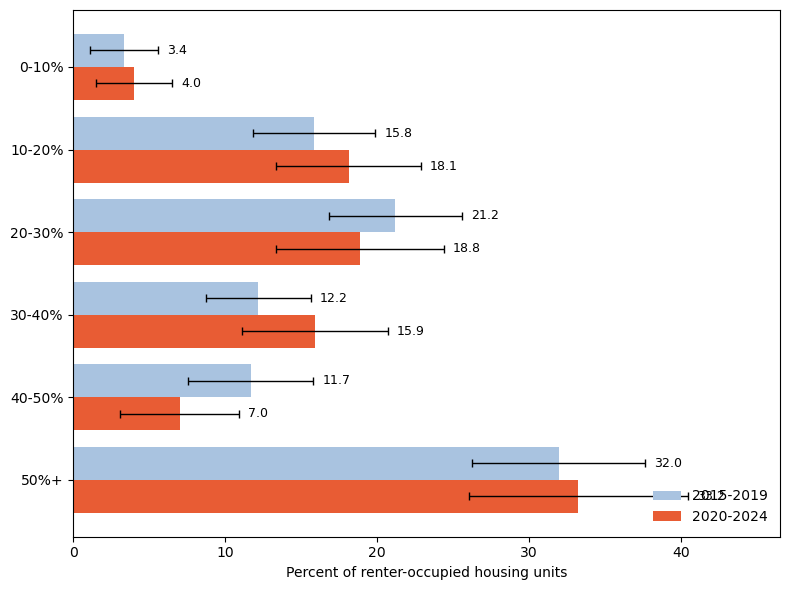

In [113]:
burden_dist_groups = ['under_10', 'btw_10_20', 'btw_20_30', 'btw_30_40', 'btw_40_50', 'over_50', 'total']

burden_dist_vars = ['under_10', 'btw_10_20', 'btw_20_30', 'btw_30_40', 'btw_40_50', 'over_50', 'total']

burden_dist_labels = {'under_10': '0-10%',
                      'btw_10_20': '10-20%',
                      'btw_20_30': '20-30%',
                      'btw_30_40': '30-40%',
                      'btw_40_50': '40-50%',
                      'over_50': '50%+',
                      'total': 'total'
                     }   

burden_dist_nbhd_comparison = combine_categories(burden_nbhd_comparison, 'btw_10_20', ['btw_10_15', 'btw_15_20'])
burden_dist_nbhd_comparison = combine_categories(burden_dist_nbhd_comparison, 'btw_20_30', ['btw_20_25', 'btw_25_30'])
burden_dist_nbhd_comparison = combine_categories(burden_dist_nbhd_comparison, 'btw_30_40', ['btw_30_35', 'btw_35_40'])

burden_dist_nbhd_comparison = add_shares(burden_dist_nbhd_comparison, groups = burden_dist_groups, total='total')

burden_dist_table_2019 = long_table(burden_dist_nbhd_comparison.loc[burden_nbhd_comparison['NAME'] == '2015-2019'],
                             groups = burden_dist_vars, 
                             labels = burden_dist_labels,
                             total = 'total')

burden_dist_table_2024 = long_table(burden_dist_nbhd_comparison.loc[burden_nbhd_comparison['NAME'] == '2020-2024'],
                             groups = burden_dist_vars, 
                             labels = burden_dist_labels,
                             total = 'total')
burden_dist_nbhd_comparison = burden_dist_nbhd_comparison.set_index('NAME')
fig, ax = grouped_hbar(burden_dist_nbhd_comparison, list(reversed(burden_dist_groups[0:6])), ['2015-2019', '2020-2024'], burden_dist_labels, 'Percent of renter-occupied housing units',
                       filename='burden_dist_grouped_bar.png', colors = ['#A9C3E0', '#E85C34'])